# 03 · Credit features and feature selection

The 21 statement ratios go into the model as delivered. A credit analyst reads them differently: as **interest coverage**, as the
**price lenders charge**, as **cash flow against what is owed**, as the **stability of profit**. The data carry ratios only, never
amounts, but many ratios share a denominator (revenue, total assets, current liabilities), so they combine into those measures.
This notebook builds 25 candidates with a credit reason each, and decides, on the training companies only, which ones the model gets
and which existing inputs it can do without.

- **Input:** `data/processed/firm_years_clean.csv`, `firm_years_naive.csv` and `schema.json` (02).
- **Output:** `data/processed/features.json` (the model's inputs: what 04 reads), `firm_years_features.csv` and
  `firm_years_naive_features.csv` (the clean rows plus the selected input features), `results/feature_selection.json`, figures.
- **The holdout is never used here.** Every number comes from the 469 training companies; 04 reads the holdout once, at the end.

**The process:**
1. **Build** the candidates (`cyber_credit/features.py`): leverage and coverage, profitability, earnings quality, liquidity,
   investment, classic scores, the company's own history, and position against its sector.
2. **Filter** (each candidate alone). A candidate goes on only if (a) at most half its values are missing; (b) it separates
   investment from speculative grade on its own: the 95% company-bootstrap interval of its AUC excludes 0.5; (c) where credit logic
   gives a direction, the data agree with it; (d) it is not a near-copy of an input the model already has or of a stronger candidate
   (rank correlation |ρ| ≥ 0.9; trees see a ranking, so a near-perfect rank correlation adds nothing).
3. **Forward selection** (a wrapper, the candidates together). Starting from the model before this notebook (21 ratios, 6 flags,
   sector), add at each step the candidate that raises company-grouped CV AUC most (15 folds: 5 folds × seeds 11/22/33, as in 04).
   Then keep **the shortest path within one standard error of the best**: the same one-SE rule 04 uses for the model's size.
4. **Backward elimination** of the existing inputs that are not protected. The ratios a cyber attack moves (margins, returns, cash
   flow, debt ratio, liquidity, turnover, days sales outstanding) and the flags the shock or the grade rule use are protected: the
   stress test needs them. The other inputs are removed one group at a time, and the fewest inputs are kept whose CV AUC stays within
   one standard error of **the best model found anywhere in the search**. One line for the whole search, not one per stage: applied
   stage by stage, each stage can give up one SE, and the end point can fall below the line of the best model. (A first run used the
   stage-by-stage version and did exactly that; section 5 prints what it would have chosen.)
5. **Confirm:** each chosen feature must beat shuffled "shadow" copies and pure noise on permutation importance; the gain must hold
   on resampled training companies; and the model must still never read a bigger loss as safer.

Feature importance alone is not the selection rule: importance says what a model *uses*, not what helps it *predict companies it has
not seen*. Correlated inputs share importance, and noise can look important. So importance is a check (step 5), not the criterion.

In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message=".*does not have valid feature names.*")
warnings.filterwarnings("ignore", message=".*TreeExplainer shap values output has changed.*")

import cloudpickle  # noqa: F401  (same environment as 04)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from joblib import Parallel, delayed
from lightgbm import LGBMClassifier
from scipy.stats import spearmanr
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT))
from cyber_credit.features import (CANDIDATES, PROTECTED, PROTECTED_FLAGS, REMOVABLE, CreditFeatures,  # noqa: E402
                                   input_features)
from cyber_credit.preprocess import Winsorizer  # noqa: E402
from cyber_credit.shock import MAX_COST, fit_reference, incident_shock  # noqa: E402
from cyber_credit.split import holdout_companies  # noqa: E402

DATA, RES, FIG = ROOT / "data" / "processed", ROOT / "results", ROOT / "figures"
SLIDES = FIG / "slides"; SLIDES.mkdir(parents=True, exist_ok=True)
NUMBERS = {}   # written to results/feature_selection.json at the end
N_JOBS = os.cpu_count()   # every fit is single-threaded and deterministic, so running them side by side changes no number


def keep(key, value, digits=4):
    # Store a number (or a nested dict/list of numbers) for the results file.
    def r(v):
        if isinstance(v, dict): return {str(k): r(x) for k, x in v.items()}
        if isinstance(v, (list, tuple, np.ndarray)): return [r(x) for x in v]
        if isinstance(v, (bool, np.bool_)): return bool(v)
        if isinstance(v, (int, np.integer)): return int(v)
        if isinstance(v, (float, np.floating)): return round(float(v), digits) if np.isfinite(v) else None
        return v
    NUMBERS[key] = r(value)

/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Training companies only
The holdout is the one 04 sets aside (same rule, `cyber_credit/split.py`); it is removed before anything is computed.

In [2]:
SCHEMA = json.loads((DATA / "schema.json").read_text())
FEATURES, FLAGS = SCHEMA["features"], SCHEMA["flags"]          # the 21 statement ratios and 6 flags of the model before this notebook
data = pd.read_csv(DATA / "firm_years_clean.csv", parse_dates=["Date"])
holdout = holdout_companies(data)
if (RES / "holdout_companies.csv").exists():
    assert holdout == set(pd.read_csv(RES / "holdout_companies.csv").Name), "holdout list changed"

inputs_all = input_features(data, list(CANDIDATES))           # the "hold" candidates: learn nothing from data, so safe on all rows
data = data.join(inputs_all)
train = data[~data.Name.isin(holdout)].reset_index(drop=True)
y = train.SG.values
print(f"training: {train.Name.nunique()} companies, {len(train)} firm-years (holdout of {len(holdout)} companies never used here)")
assert set(PROTECTED) | {c for g in REMOVABLE.values() for c in g if c in FEATURES} == set(FEATURES)
assert set(PROTECTED_FLAGS) | {c for g in REMOVABLE.values() for c in g if c in FLAGS} == set(FLAGS)
keep("training", {"companies": train.Name.nunique(), "firm_years": len(train)})

training: 469 companies, 1619 firm-years (holdout of 123 companies never used here)


## 2. The candidates
Each one, its formula, the credit question it answers, the direction credit logic expects (+1 riskier when higher, −1 safer when
higher, 0 none) and how the cyber shock treats it: **recompute** (built inside the model from the ratios, so it follows the shock)
or **hold** (an input column kept at today's value). A feature is held when the shock would move it the wrong way (the implied rate
falls when debt rises but interest does not) or when it describes history, not this year.

In [3]:
catalog = pd.DataFrame([{"feature": n, "label": c.label, "family": c.family, "formula": c.formula, "why": c.why,
                         "direction": c.direction, "shock": c.shock} for n, c in CANDIDATES.items()]).set_index("feature")
with pd.option_context("display.max_colwidth", 70, "display.width", 250):
    print(catalog[["label", "family", "direction", "shock", "formula"]].to_string())
keep("candidates", catalog.drop(columns=["why"]).to_dict(orient="index"))

                                                       label                 family  direction      shock                                                                                           formula
feature                                                                                                                                                                                                    
coverage                                   Interest coverage  leverage and coverage         -1  recompute                                            operating margin / (operating margin - pre-tax margin)
implied_rate                           Implied interest rate  leverage and coverage          1       hold                                 (operating margin - pre-tax margin) x asset turnover / debt ratio
ocf_liab                   Operating cash flow / liabilities  leverage and coverage         -1       hold                                                           OCF/sales x asset tu

## 3. Filter: each candidate on its own
Values on the training rows (sector medians from the training rows; inside cross-validation they are learned per fold). AUC is
oriented so that 0.5 means no separation and above 0.5 means "riskier when higher"; its interval resamples companies.

In [4]:
def candidate_values(frame, names, fit_on=None):
    # Values of the candidates on `frame`: hold ones are columns, recompute ones come from CreditFeatures fitted on `fit_on`.
    rec = [n for n in names if CANDIDATES[n].shock == "recompute"]
    out = frame[[n for n in names if n not in rec]].copy()
    if rec:
        made = CreditFeatures(rec).fit(frame if fit_on is None else fit_on).transform(frame)
        out[rec] = made[rec]
    return out[names]


def company_ci(stat, frame, n=1000, seed=0):
    # 95% interval of stat(frame) when companies are resampled (as in 04).
    rng, groups = np.random.default_rng(seed), frame.groupby("Name").indices
    keys = np.array(list(groups))
    out = [stat(frame.iloc[np.concatenate([groups[k] for k in rng.choice(keys, len(keys))])]) for _ in range(n)]
    return np.percentile(out, [2.5, 97.5])


values = candidate_values(train, list(CANDIDATES))
BANDS = SCHEMA["bands"]
rows = []
for n in CANDIDATES:
    v = values[n]; ok = v.notna().to_numpy()
    f = pd.DataFrame({"Name": train.Name[ok], "SG": y[ok], "v": v[ok]})
    auc = roc_auc_score(f.SG, f.v)
    lo, hi = company_ci(lambda g: roc_auc_score(g.SG, g.v), f)
    med = v.groupby(train.band).median().reindex(BANDS)
    rows.append({"feature": n, "missing": 1 - ok.mean(), "AUC": auc, "AUC lo": lo, "AUC hi": hi,
                 "data says": "riskier when higher" if auc > 0.5 else "safer when higher", **{b: med[b] for b in BANDS}})
uni = pd.DataFrame(rows).set_index("feature")

# redundancy: rank correlation with the inputs the model already has, and with stronger candidates
rho_existing = {n: max(abs(spearmanr(values[n], train[c], nan_policy="omit").statistic) for c in FEATURES) for n in CANDIDATES}
closest = {n: max(FEATURES, key=lambda c: abs(spearmanr(values[n], train[c], nan_policy="omit").statistic)) for n in CANDIDATES}
strength = (uni.AUC - 0.5).abs()
reasons = {}
for n in strength.sort_values(ascending=False).index:     # strongest first, so a candidate is compared with stronger ones only
    c, u, why = CANDIDATES[n], uni.loc[n], []
    if u.missing > 0.5: why.append("over half missing")
    if u["AUC lo"] <= 0.5 <= u["AUC hi"]: why.append("does not separate IG/SG on its own")
    if c.direction and np.sign(u.AUC - 0.5) != c.direction: why.append("data contradict the credit direction")
    if rho_existing[n] >= 0.9: why.append(f"near-copy of {closest[n]} (|rho| {rho_existing[n]:.2f})")
    stronger = [m for m, r in reasons.items() if not r]
    twins = [m for m in stronger if abs(spearmanr(values[n], values[m], nan_policy="omit").statistic) >= 0.9]
    if twins: why.append(f"near-copy of {twins[0]}")
    reasons[n] = why
uni["max |rho| with an input"] = pd.Series(rho_existing)
uni["passes"] = pd.Series({n: not r for n, r in reasons.items()})
uni["reason"] = pd.Series({n: "; ".join(r) for n, r in reasons.items()})
PASSED = [n for n in uni.sort_values("AUC", key=lambda a: -(a - 0.5).abs()).index if uni.passes[n]]
with pd.option_context("display.width", 250, "display.max_colwidth", 60):
    print(uni.sort_values("passes", ascending=False)[["missing", "AUC", "AUC lo", "AUC hi", "data says", "max |rho| with an input", "passes", "reason"]].round(3).to_string())
print(f"\n{len(PASSED)} of {len(CANDIDATES)} candidates pass the filter: {PASSED}")
keep("filter", uni.to_dict(orient="index"))
keep("passed_filter", PASSED)

                      missing    AUC  AUC lo  AUC hi            data says  max |rho| with an input  passes                                           reason
feature                                                                                                                                                    
coverage                0.000  0.273   0.239   0.308    safer when higher                    0.715    True                                                 
accruals                0.000  0.436   0.395   0.475    safer when higher                    0.381    True                                                 
d_op_margin             0.290  0.464   0.431   0.498    safer when higher                    0.306    True                                                 
op_margin_vol           0.290  0.649   0.597   0.702  riskier when higher                    0.470    True                                                 
z_partial               0.006  0.448   0.397   0.495    safer wh

**Reading:** 12 of 25 candidates pass. Out: the sector-relative operating margin and debt ratio, equity / liabilities and working
capital / assets, which are near-copies of ratios the model already has (equity / liabilities is just another way of writing the debt
ratio); the sector-relative coverage, a near-copy of coverage itself; cash runway, where the data say more cash goes with *more*
risk, as for the liquidity ratios in 04 §8, so a "more cash is safer" constraint would be wrong; and seven candidates that do not separate
investment from speculative grade on their own, among them the change in coverage and the share of fixed assets.

**Medians by rating band** (training rows) for the candidates that pass: a useful credit feature moves steadily from AA to CCC, and
moves between BBB and BB, the line the model draws.

In [5]:
print(uni.loc[PASSED, BANDS].round(3).to_string())

                     AA and above       A    BBB     BB      B  CCC and below
feature                                                                      
coverage                   50.000  13.223  6.661  3.552  1.570          0.390
ebit_ta                     0.134   0.097  0.076  0.058  0.048          0.012
ocf_liab                    0.246   0.168  0.151  0.127  0.088          0.049
op_margin_vol               0.017   0.016  0.019  0.033  0.038          0.092
implied_rate                0.001   0.013  0.018  0.026  0.033          0.034
lt_liab_ta                  0.337   0.414  0.430  0.459  0.555          0.678
fcf_liab                    0.141   0.112  0.082  0.072  0.040          0.013
accruals                   -0.043  -0.039 -0.044 -0.051 -0.054         -0.050
capex_rev                   0.045   0.036  0.046  0.036  0.038          0.028
ocf_sales_vs_sector         0.032   0.010  0.006 -0.005 -0.028         -0.077
z_partial                   2.405   1.851  1.734  1.775  1.438  

## 4. Forward selection: the candidates together
The model is the current champion of 04 (monotone LightGBM, 200 trees × 5 leaves, the same preprocessing), with each candidate's
credit direction as its monotone constraint. The current model's CV AUC is checked against 04's number of record first, so the
comparison starts from the model actually in use.

In [6]:
SAFER = ["returnOnAssets", "returnOnCapitalEmployed", "netProfitMargin", "pretaxProfitMargin", "operatingProfitMargin",
         "ebitPerRevenue", "operatingCashFlowSalesRatio", "returnOnEquity", "freeCashFlowOperatingCashFlowRatio"]   # as 04 §3
RISKIER = ["debtRatio", "roe_negative", "negative_equity", "ocf_negative"]
DIRECTION = {**{c: -1 for c in SAFER}, **{c: 1 for c in RISKIER}, **{n: c.direction for n, c in CANDIDATES.items()}}
LGB = {"n_estimators": 200, "learning_rate": 0.03, "num_leaves": 5, "min_child_samples": 20, "subsample": 0.8, "subsample_freq": 1,
       "colsample_bytree": 0.8, "random_state": 0, "n_jobs": 1, "deterministic": True, "force_row_wise": True, "verbose": -1}
LEVELS = sorted(data.Sector.unique())
SEEDS = (11, 22, 33)
FOLDS = [(fit, score) for seed in SEEDS
         for fit, score in StratifiedGroupKFold(5, shuffle=True, random_state=seed).split(train, y, groups=train.Name)]


def build(numeric, computed, flags, lgb=LGB):
    # The model: credit features computed from the ratios, then median fill and winsorising, flags, sector; monotone LightGBM.
    cols = ColumnTransformer([("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("winsor", Winsorizer())]), numeric + computed),
                              ("flag", "passthrough", flags),
                              ("cat", OneHotEncoder(categories=[LEVELS], handle_unknown="ignore", sparse_output=False), ["Sector"])])
    mono = [DIRECTION.get(c, 0) for c in numeric + computed + flags] + [0] * len(LEVELS)
    return Pipeline([("pre", Pipeline([("credit", CreditFeatures(computed)), ("columns", cols)])),
                     ("model", LGBMClassifier(monotone_constraints=mono, **lgb))])


def spec_add(spec, n):
    # The spec with candidate n added where it belongs: computed in the model (recompute) or an input column (hold).
    key = "computed" if CANDIDATES[n].shock == "recompute" else "numeric"
    return {**spec, key: spec[key] + [n]}


def spec_drop(spec, group):
    return {k: [c for c in v if c not in REMOVABLE[group]] for k, v in spec.items()}


def size(spec):
    return sum(len(v) for v in spec.values())


def _fold(spec, i, frame=None, target=None, folds=None):
    frame, target, folds = (train, y, FOLDS) if frame is None else (frame, target, folds)
    fit, score = folds[i]
    m = build(**spec).fit(frame.iloc[fit], target[fit])
    return roc_auc_score(target[score], m.predict_proba(frame.iloc[score])[:, 1])


def cv_many(specs):
    # Per-fold AUC (15 folds) for each spec; all fits run in parallel, each one deterministic.
    out = Parallel(n_jobs=N_JOBS)(delayed(_fold)(s, i) for s in specs for i in range(len(FOLDS)))
    return [np.array(out[k * len(FOLDS):(k + 1) * len(FOLDS)]) for k in range(len(specs))]


CURRENT = {"numeric": list(FEATURES), "computed": [], "flags": list(FLAGS)}   # the model before this notebook: 21 ratios, 6 flags, sector
current_folds = cv_many([CURRENT])[0]
BEFORE = 0.812   # 04's champion before the credit features (results/numbers_of_record.json at commit 4acdfde, model_comparison_cv)
print(f"starting model: CV AUC {current_folds.mean():.4f} (04's champion before the credit features: {BEFORE})")
assert abs(current_folds.mean() - BEFORE) < 0.0006, "the starting point is not 04's champion"

/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site

starting model: CV AUC 0.8122 (04's champion before the credit features: 0.812)


/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site

In [7]:
MAX_STEPS = 8
path, spec, pool = [{"step": 0, "change": "start: 21 ratios, 6 flags", "spec": CURRENT, "folds": current_folds}], CURRENT, list(PASSED)
while pool and len(path) <= MAX_STEPS:
    tried = [spec_add(spec, n) for n in pool]
    scores = cv_many(tried)
    k = int(np.argmax([s.mean() for s in scores]))
    spec = tried[k]
    path.append({"step": len(path), "change": f"+ {pool[k]}", "spec": spec, "folds": scores[k],
                 "runner_up": pool[int(np.argsort([-s.mean() for s in scores])[1])] if len(pool) > 1 else None})
    print(f"step {len(path) - 1}: + {pool[k]:22s} CV AUC {scores[k].mean():.4f}  (gain {scores[k].mean() - path[-2]['folds'].mean():+.4f})")
    pool.pop(k)

fwd = pd.DataFrame([{"step": p["step"], "change": p["change"], "inputs": size(p["spec"]), "cv_auc": p["folds"].mean(),
                     "se": p["folds"].std(ddof=1) / np.sqrt(len(p["folds"])),
                     "gain_vs_current": (p["folds"] - current_folds).mean(),
                     "gain_sd_over_folds": (p["folds"] - current_folds).std(ddof=1)} for p in path])
best = fwd.loc[fwd.cv_auc.idxmax()]
chosen_step = int(fwd[fwd.cv_auc >= best.cv_auc - best.se].step.min())
FORWARD = path[chosen_step]["spec"]
print(f"\nbest: step {best.step:.0f}, CV AUC {best.cv_auc:.4f}, one SE {best.se:.4f} -> shortest path within one SE: step {chosen_step}")
print("added:", [c for c in FORWARD["numeric"] + FORWARD["computed"] if c in CANDIDATES])
keep("forward_path", fwd.to_dict(orient="records"))
keep("forward_choice", {"best_step": int(best.step), "best_cv_auc": best.cv_auc, "one_se": best.se, "chosen_step": chosen_step})

/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site

/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site

/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site

/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site

/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site

...

/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site

/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site

step 8: + ocf_sales_vs_sector    CV AUC 0.8331  (gain -0.0009)

best: step 7, CV AUC 0.8340, one SE 0.0065 -> shortest path within one SE: step 2
added: ['implied_rate', 'op_margin_vol']


/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site

**Reading:** the **implied interest rate** enters first and adds the most (+0.012 AUC), **operating-margin volatility** second (+0.005).
Interest coverage comes third but adds only +0.001 once the implied rate is in: both read the same line of the income statement
(operating minus pre-tax profit, the interest burden), and the implied rate, which sets it against everything the company owes,
carries more. The next five steps add +0.005 together, within one standard error of noise, so the path stops at two.

## 5. Backward elimination: the existing inputs that are not protected
Starting from the forward choice, remove at each step the group whose removal costs least. Then keep the fewest inputs whose CV AUC
stays within one standard error of the best model found anywhere in the search, forward or backward. The stage-by-stage version
(the best of this path only), which a first run used, is printed too: it gives up more AUC, because each stage takes its own
one-SE step down.

In [8]:
bpath, spec, groups = [{"step": 0, "change": "forward choice", "spec": FORWARD, "folds": path[chosen_step]["folds"]}], FORWARD, list(REMOVABLE)
while groups:
    tried = [spec_drop(spec, g) for g in groups]
    scores = cv_many(tried)
    k = int(np.argmax([s.mean() for s in scores]))
    spec = tried[k]
    bpath.append({"step": len(bpath), "change": f"- {groups[k]}", "spec": spec, "folds": scores[k]})
    print(f"step {len(bpath) - 1}: - {groups[k]:20s} CV AUC {scores[k].mean():.4f}  (change {scores[k].mean() - bpath[-2]['folds'].mean():+.4f})")
    groups.pop(k)

bwd = pd.DataFrame([{"step": p["step"], "change": p["change"], "inputs": size(p["spec"]), "cv_auc": p["folds"].mean(),
                     "se": p["folds"].std(ddof=1) / np.sqrt(len(p["folds"]))} for p in bpath])
searched = pd.concat([fwd.assign(stage="forward"), bwd.assign(stage="backward")], ignore_index=True)
gbest = searched.loc[searched.cv_auc.idxmax()]
LINE = gbest.cv_auc - gbest.se                                   # one line for the whole search
bchosen = int(bwd[bwd.cv_auc >= LINE].sort_values(["inputs", "cv_auc"], ascending=[True, False]).step.iloc[0])
bbest = bwd.loc[bwd.cv_auc.idxmax()]
stagewise = int(bwd[bwd.cv_auc >= bbest.cv_auc - bbest.se].sort_values("inputs").step.iloc[0])
FINAL, final_folds = bpath[bchosen]["spec"], bpath[bchosen]["folds"]
removed = [c for c in FEATURES + FLAGS if c not in FINAL["numeric"] + FINAL["flags"]]
added = [c for c in FINAL["numeric"] + FINAL["computed"] if c in CANDIDATES]
print(f"\nbest model in the whole search: {gbest.stage} step {gbest.step:.0f}, CV AUC {gbest.cv_auc:.4f}, one SE {gbest.se:.4f}"
      f" -> line {LINE:.4f}; fewest inputs above it: backward step {bchosen}")
print(f"stage-by-stage rule (not used): backward step {stagewise}, CV AUC {bwd.cv_auc[stagewise]:.4f}"
      f" ({'below' if bwd.cv_auc[stagewise] < LINE else 'above'} the line)")
print(f"final: {size(FINAL)} inputs (+ sector) | added {added} | removed {removed}")
print(f"CV AUC {current_folds.mean():.4f} -> {final_folds.mean():.4f} (gain {(final_folds - current_folds).mean():+.4f},"
      f" sd over the 15 folds {(final_folds - current_folds).std(ddof=1):.4f}; better in {(final_folds > current_folds).sum()} of 15 folds)")
keep("backward_path", bwd.to_dict(orient="records"))
keep("backward_choice", {"search_best_stage": gbest.stage, "search_best_step": int(gbest.step), "search_best_cv_auc": gbest.cv_auc,
                         "one_se": gbest.se, "line": LINE, "chosen_step": bchosen,
                         "stagewise_rule_step": stagewise, "stagewise_rule_cv_auc": bwd.cv_auc[stagewise]})
keep("final", {"added": added, "removed": removed, "inputs": size(FINAL), "cv_auc_current": current_folds.mean(), "cv_auc_final": final_folds.mean(),
               "gain": (final_folds - current_folds).mean(), "gain_sd_over_folds": (final_folds - current_folds).std(ddof=1),
               "folds_better": int((final_folds > current_folds).sum())})

/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site

/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site

/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site

/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site

/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site

...

/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site

step 5: - debt / equity        CV AUC 0.8291  (change -0.0004)


/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site

step 6: - effective tax rate   CV AUC 0.8268  (change -0.0023)

best model in the whole search: forward step 7, CV AUC 0.8340, one SE 0.0065 -> line 0.8276; fewest inputs above it: backward step 5
stage-by-stage rule (not used): backward step 6, CV AUC 0.8268 (below the line)
final: 22 inputs (+ sector) | added ['implied_rate', 'op_margin_vol'] | removed ['grossProfitMargin', 'debtEquityRatio', 'companyEquityMultiplier', 'payablesTurnover', 'cogs_not_reported', 'payables_zero', 'dso_zero']
CV AUC 0.8122 -> 0.8291 (gain +0.0168, sd over the 15 folds 0.0141; better in 13 of 15 folds)


/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


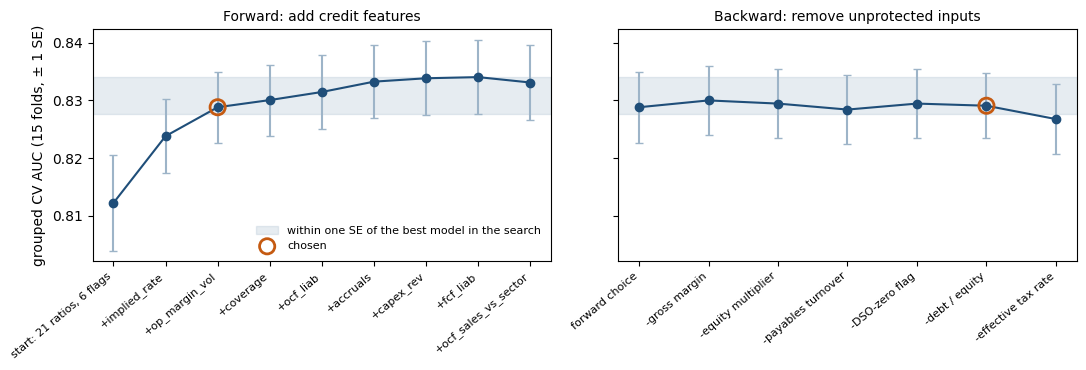

In [9]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, t, choice, title in [(a, fwd, chosen_step, "Forward: add credit features"), (b, bwd, bchosen, "Backward: remove unprotected inputs")]:
    ax.errorbar(t.step, t.cv_auc, yerr=t.se, fmt="o-", color="#1f4e79", ecolor="#9db4c8", capsize=3)
    ax.axhspan(LINE, gbest.cv_auc, color="#9db4c8", alpha=0.25, label="within one SE of the best model in the search")
    ax.scatter([choice], [t.set_index("step").cv_auc[choice]], s=120, facecolors="none", edgecolors="#c55a11", lw=2, zorder=3, label="chosen")
    ax.set_xticks(t.step, [c.replace("+ ", "+").replace("- ", "-") for c in t.change], rotation=40, ha="right", fontsize=8)
    ax.set_title(title, fontsize=10)
a.set_ylabel("grouped CV AUC (15 folds, ± 1 SE)"); a.legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout(); fig.savefig(FIG / "fig_feature_selection.png", dpi=150); plt.show()

**Reading:** removing gross margin even helps a little (a fifth of its values were unreported and blanked). Debt / equity and the
equity multiplier add nothing: both are the debt ratio written another way (liabilities ÷ equity and assets ÷ equity), and a tree
model reads the same ranking from the debt ratio. Payables turnover and the placeholder flags add nothing either. The effective tax
rate stays: removing it as well would cost 0.002 and take the model below the line. The model ends with fewer inputs than it started
with and a higher CV AUC.

## 6. Confirm the choice
**Shadow check.** The final model is refitted with, for every feature, a "shadow": the same values shuffled across rows, so it keeps
the distribution but loses any link to the rating, plus three columns of pure noise (the idea of Boruta). Permutation importance is
measured on held-out companies (the AUC lost when a column is shuffled in the fold the model did not see). Every feature the
selection added must beat the strongest shadow.

In [10]:
rng = np.random.default_rng(0)
shadow_train = train.copy()
added_inputs = [c for c in FINAL["numeric"] if c in CANDIDATES]
sources = {}
for c in FINAL["numeric"] + FINAL["computed"]:
    v = candidate_values(train, [c])[c] if c in CANDIDATES else train[c]
    shadow_train[f"shadow_{c}"] = rng.permutation(v.to_numpy()); sources[f"shadow_{c}"] = c
for i in range(3):
    shadow_train[f"noise_{i}"] = rng.normal(size=len(train))
SHADOWS = [c for c in shadow_train.columns if c.startswith(("shadow_", "noise_"))]
shadow_spec = {**FINAL, "numeric": FINAL["numeric"] + SHADOWS}


def perm_importance(i, repeats=5):
    fit, score = FOLDS[i]
    m = build(**shadow_spec).fit(shadow_train.iloc[fit], y[fit])
    X = m.named_steps["pre"].transform(shadow_train.iloc[score]); clf = m.named_steps["model"]
    base = roc_auc_score(y[score], clf.predict_proba(X)[:, 1])
    names = shadow_spec["numeric"] + shadow_spec["computed"]
    out, r = {}, np.random.default_rng(i)
    for j, name in enumerate(names):
        drops = []
        for _ in range(repeats):
            Xp = X.copy(); Xp[:, j] = r.permutation(Xp[:, j])
            drops.append(base - roc_auc_score(y[score], clf.predict_proba(Xp)[:, 1]))
        out[name] = np.mean(drops)
    return out


imp = pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(perm_importance)(i) for i in range(len(FOLDS)))).mean()
shadow_max = imp[SHADOWS].max()
check = pd.DataFrame({"permutation importance (AUC lost)": imp[added], "beats strongest shadow": imp[added] > shadow_max})
print(f"strongest shadow: {imp[SHADOWS].idxmax()} ({shadow_max:.4f})")
print(check.round(4).to_string())
ranked = imp.drop(SHADOWS).sort_values(ascending=False)
print("\nall model inputs by permutation importance (rank of the added ones):",
      {c: int(ranked.index.get_loc(c)) + 1 for c in added}, f"of {len(ranked)}")
assert check["beats strongest shadow"].all(), "an added feature does not beat the shadows"
keep("shadow_check", {"strongest_shadow": imp[SHADOWS].idxmax(), "strongest_shadow_importance": shadow_max,
                      "added": check["permutation importance (AUC lost)"].to_dict(),
                      "rank_of_added": {c: int(ranked.index.get_loc(c)) + 1 for c in added}, "inputs_ranked": len(ranked)})

/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site

/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site

/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site

/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site

/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site

...

/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site

/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site

/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site

strongest shadow: shadow_implied_rate (0.0005)
               permutation importance (AUC lost)  beats strongest shadow
implied_rate                              0.0319                    True
op_margin_vol                             0.0059                    True

all model inputs by permutation importance (rank of the added ones): {'implied_rate': 1, 'op_margin_vol': 7} of 19


/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site

**SHAP on the final model** (fitted on all training companies, explained on them): where the added features sit among all inputs.

In [11]:
final_model = build(**FINAL).fit(train, y)
Xs = final_model.named_steps["pre"].transform(train)
sv = shap.TreeExplainer(final_model.named_steps["model"]).shap_values(Xs)
sv = sv[1] if isinstance(sv, list) else sv
shap_names = FINAL["numeric"] + FINAL["computed"] + FINAL["flags"] + [f"Sector={s}" for s in LEVELS]
mean_abs = pd.Series(np.abs(sv).mean(0), index=shap_names).sort_values(ascending=False)
print(mean_abs.head(12).round(3).to_string())
print("rank by mean |SHAP|:", {c: int(mean_abs.index.get_loc(c)) + 1 for c in added}, f"of {len(mean_abs)}")
keep("shap_rank_of_added", {c: int(mean_abs.index.get_loc(c)) + 1 for c in added})
keep("shap_top10", mean_abs.head(10).to_dict())

implied_rate                   0.401
debtRatio                      0.330
operatingCashFlowSalesRatio    0.299
returnOnCapitalEmployed        0.252
ebitPerRevenue                 0.178
cashRatio                      0.168
returnOnAssets                 0.161
op_margin_vol                  0.160
assetTurnover                  0.118
currentRatio                   0.112
fixedAssetTurnover             0.111
Sector=Public Utilities        0.103
rank by mean |SHAP|: {'implied_rate': 1, 'op_margin_vol': 8} of 34


**Reading:** both added features beat every shadow and the noise columns by a wide margin. The implied interest rate is the most
important input of the whole model, on permutation importance and on SHAP; margin volatility ranks seventh to eighth.

**What the implied rate measures, and its caveats.** Interest paid per unit owed: lenders charge riskier borrowers more, so it reads
the lenders' own view of the company. For a rated company part of that price follows the rating itself, so the feature partly carries
the label's consequence; for an unrated company, which the model is for, the price its lenders charge is real information about its
risk. It is a proxy: the gap between operating and pre-tax profit also holds other non-operating items, and the denominator counts
liabilities that bear no interest, such as payables. Under the cyber shock it is held at today's value: the stress test adds no
interest on new debt and no spread widening, so it understates that channel.

**Stability.** The comparison is repeated on 20 random draws of 80% of the training companies (5 company-grouped folds each): does
the final set still beat the starting model when the companies change?

In [12]:
def resample_gain(r):
    names = np.random.default_rng(100 + r).permutation(train.Name.unique())[: int(0.8 * train.Name.nunique())]
    sub = train[train.Name.isin(set(names))].reset_index(drop=True); ys = sub.SG.values
    folds = list(StratifiedGroupKFold(5, shuffle=True, random_state=r).split(sub, ys, groups=sub.Name))
    a = np.mean([_fold(CURRENT, i, sub, ys, folds) for i in range(5)])
    b = np.mean([_fold(FINAL, i, sub, ys, folds) for i in range(5)])
    return b - a


gains = np.array(Parallel(n_jobs=N_JOBS)(delayed(resample_gain)(r) for r in range(20)))
print(f"gain over the starting model in 20 resamples: median {np.median(gains):+.4f}, positive in {(gains > 0).sum()} of 20,"
      f" range {gains.min():+.4f} to {gains.max():+.4f}")
keep("stability", {"resamples": 20, "median_gain": np.median(gains), "positive": int((gains > 0).sum()), "min": gains.min(), "max": gains.max()})

/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site

/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site

/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site

/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site

/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site

...

/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site

/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site

/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site

gain over the starting model in 20 resamples: median +0.0166, positive in 20 of 20, range +0.0077 to +0.0242


/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ayush.singh/ayush-hec/Cyber-Credit-Risk/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


**The cyber shock still works.** On each training company's latest statement, P(SG) must never fall as an incident cost grows from
0 to 30% of revenue (the model's raw score, fitted on the training companies), and every recomputed feature must move towards more risk.

In [13]:
latest = train.sort_values("Date").groupby("Name").tail(1)
ref = fit_reference(train)
costs = np.linspace(0, MAX_COST, 61)
scores = np.column_stack([final_model.predict_proba(incident_shock(latest, c, ref))[:, 1] for c in costs])
violations = int((np.diff(scores, axis=1) < -1e-9).any(axis=1).sum())
print(f"companies whose score ever falls as the cost grows: {violations} of {len(latest)}")
made_before = CreditFeatures(FINAL["computed"]).fit(train).transform(latest)
made_after = CreditFeatures(FINAL["computed"]).fit(train).transform(incident_shock(latest, 0.05, ref))
for c in FINAL["computed"]:
    worse = (made_after[c] - made_before[c]) * CANDIDATES[c].direction >= -1e-12
    print(f"{c}: moves towards risk (or stays) under a 5% cost for {worse.mean():.0%} of companies")
    assert worse.all()
assert violations == 0
keep("shock_check", {"companies": len(latest), "score_falls": violations})

companies whose score ever falls as the cost grows: 0 of 469


## 7. What the model gets
The selected input features are written next to the clean rows; `features.json` lists the model's inputs, which 04 reads.

In [14]:
naive = pd.read_csv(DATA / "firm_years_naive.csv", parse_dates=["Date"])
held = [c for c in FINAL["numeric"] if c in CANDIDATES]
clean_out = pd.read_csv(DATA / "firm_years_clean.csv", parse_dates=["Date"])
for name, frame in [("firm_years_features", clean_out), ("firm_years_naive_features", naive)]:
    out = frame.join(input_features(frame, held)) if held else frame
    out.to_csv(DATA / f"{name}.csv", index=False, date_format="%Y-%m-%d")
    print(f"{name}.csv: {out.shape}")
spec_out = {**FINAL, "added": added, "removed": removed,
            "directions": {c: CANDIDATES[c].direction for c in added},
            "labels": {c: CANDIDATES[c].label for c in added},
            "rule": "03_features: filter, forward selection and backward elimination on grouped CV, one-SE rule; training companies only"}
(DATA / "features.json").write_text(json.dumps(spec_out, indent=1))
print(json.dumps({k: spec_out[k] for k in ["added", "removed", "computed"]}, indent=1))

firm_years_features.csv: (2028, 44)


firm_years_naive_features.csv: (2432, 44)
{
 "added": [
  "implied_rate",
  "op_margin_vol"
 ],
 "removed": [
  "grossProfitMargin",
  "debtEquityRatio",
  "companyEquityMultiplier",
  "payablesTurnover",
  "cogs_not_reported",
  "payables_zero",
  "dso_zero"
 ],
 "computed": []
}


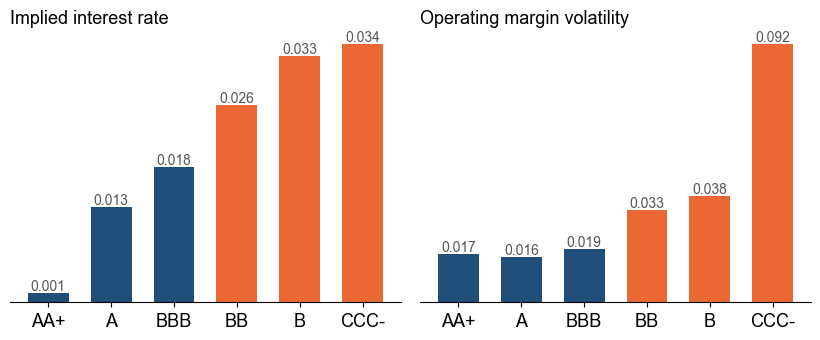

In [15]:
# Figure for the presentation: the added features by rating band (training rows), in the deck style of 01 section 15
plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"], "font.size": 13,
                     "axes.spines.top": False, "axes.spines.right": False})
show = added
fig, axes = plt.subplots(1, len(show), figsize=(4.2 * len(show), 3.6), squeeze=False)
short = ["AA+", "A", "BBB", "BB", "B", "CCC-"]
for ax, c in zip(axes[0], show):
    med = uni.loc[c, BANDS].astype(float).to_numpy()
    ax.bar(range(6), med, color=["#1f4e79"] * 3 + ["#eb6834"] * 3, width=0.65)
    for i, v in enumerate(med):
        ax.text(i, v, f"{v:.1f}" if abs(v) >= 1 else f"{v:.3f}", ha="center", va="bottom", fontsize=10, color="#555555")
    ax.set_xticks(range(6), short); ax.set_yticks([]); ax.spines["left"].set_visible(False)
    ax.set_title(CANDIDATES[c].label, fontsize=13, loc="left")
fig.tight_layout(); fig.savefig(SLIDES / "credit_features_by_band.png", dpi=200); plt.show()

In [16]:
(RES / "feature_selection.json").write_text(json.dumps(NUMBERS, indent=1, ensure_ascii=False))
print(f"{len(NUMBERS)} entries written to results/feature_selection.json")

14 entries written to results/feature_selection.json
